<a href="https://colab.research.google.com/github/sonalimoorthy/SC4002-NLP-PROJECT-/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SC4002 NLP Project — Task 1 and Task 2

This notebook trains and compares two RNN models on the MASSIVE English dataset.

- **Task 1 — Intent classification:** predict one of the 60 intent labels for an utterance.
- **Task 2 — Slot filling:** predict a BIO slot label for each token in the utterance.

Both tasks use the same RNN encoder, with a separate output layer for each task.

## Experiments
1. **Unidirectional RNN:** reads the utterance from left to right.
2. **Bidirectional RNN:** reads the utterance from left to right and right to left.

The models use word embeddings, RNNs, softmax outputs and cross-entropy loss, following the SC4002 lecture material.

## 1. Imports and setup

The imports below are used for loading the data, building the neural networks, training them and checking their results.

In [1]:
import json
import random
import re
import tarfile
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)


Device: cpu


## 2. Load the MASSIVE English dataset

The notebook first checks whether the original JSONL file or a processed train/dev/test split is already available. If neither is found, it downloads the official MASSIVE archive.

In [2]:
DATA_URL = 'https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz'

RAW_JSONL = Path('data/raw/en-US.jsonl')
RAW_ARCHIVE = Path('data/raw/amazon-massive-dataset-1.0.tar.gz')
PROCESSED_DIR = Path('data/processed')

if not RAW_JSONL.is_file() and not RAW_ARCHIVE.is_file():
    for root in [Path('.'), Path('/kaggle/input')]:
        if root.exists():
            files = list(root.rglob('en-US.jsonl'))
            if files:
                RAW_JSONL = files[0]
                print('Found dataset:', RAW_JSONL)
                break

if not RAW_JSONL.is_file() and not RAW_ARCHIVE.is_file():
    for root in [Path('.'), Path('/kaggle/input')]:
        if root.exists():
            files = [p for p in root.rglob('*.tar.gz') if 'massive' in p.name.lower()]
            if files:
                RAW_ARCHIVE = files[0]
                print('Found archive:', RAW_ARCHIVE)
                break

if not RAW_JSONL.is_file() and not RAW_ARCHIVE.is_file():
    RAW_ARCHIVE.parent.mkdir(parents=True, exist_ok=True)
    print('Downloading MASSIVE dataset...')
    urllib.request.urlretrieve(DATA_URL, RAW_ARCHIVE)


## 3. Tokenisation and reading the data

The tokeniser separates words and punctuation and converts tokens to lowercase. The same tokenisation is applied to the utterance and its slot annotations so that each input token has one slot label.

In [3]:
TOKEN_PATTERN = re.compile(r"\w+(?:['’]\w+)*|[^\w\s]", flags=re.UNICODE)
SLOT_PATTERN = re.compile(r'\[([^:\]]+)\s*:\s*(.*?)\]')


def tokenize_utterance(text):
    return [word.lower() for word in TOKEN_PATTERN.findall(str(text))]


def read_jsonl(path):
    rows = []
    with Path(path).open('r', encoding='utf-8-sig') as file:
        for line in file:
            if line.strip():
                rows.append(json.loads(line))
    return rows


def read_archive(path):
    with tarfile.open(path, mode='r:gz') as archive:
        member = next(
            (item for item in archive if item.isfile() and item.name.endswith('/data/en-US.jsonl')),
            None
        )
        if member is None:
            raise FileNotFoundError('Could not find data/en-US.jsonl in the archive')

        stream = archive.extractfile(member)
        if stream is None:
            raise FileNotFoundError('Could not read the MASSIVE JSONL file')

        return [json.loads(line.decode('utf-8')) for line in stream if line.strip()]


def parse_annot_utt(annot_utt):
    words = []
    tags = []
    position = 0

    for match in SLOT_PATTERN.finditer(str(annot_utt)):
        outside = tokenize_utterance(annot_utt[position:match.start()])
        words.extend(outside)
        tags.extend(['O'] * len(outside))

        slot_name = match.group(1).strip()
        slot_words = tokenize_utterance(match.group(2).strip())

        if slot_words:
            words.extend(slot_words)
            tags.append('B-' + slot_name)
            tags.extend(['I-' + slot_name] * (len(slot_words) - 1))

        position = match.end()

    outside = tokenize_utterance(str(annot_utt)[position:])
    words.extend(outside)
    tags.extend(['O'] * len(outside))

    return words, tags


## 4. Prepare train, development and test data

The original MASSIVE partitions are kept. Slot labels are read from the annotated utterance when available. The code also accepts already processed rows that store their slot labels in `slots`, `slot_tags` or `slot_labels`.

In [4]:
def load_processed_splits(folder):
    result = {}
    for split in ['train', 'dev', 'test']:
        file_path = folder / (split + '.jsonl')
        if not file_path.is_file():
            return None
        result[split] = read_jsonl(file_path)
    return result


split_rows = load_processed_splits(PROCESSED_DIR)

if split_rows is not None:
    print('Using processed train/dev/test files.')
else:
    if RAW_JSONL.is_file():
        raw_rows = read_jsonl(RAW_JSONL)
    else:
        raw_rows = read_archive(RAW_ARCHIVE)

    split_rows = {'train': [], 'dev': [], 'test': []}

    for row in raw_rows:
        if row.get('locale') == 'en-US':
            split = row.get('partition')
            if split in split_rows:
                split_rows[split].append(row)

    print('Using original MASSIVE English records.')


data = {}

for split in ['train', 'dev', 'test']:
    cleaned = []

    for row in split_rows[split]:
        utterance = row.get('utt', row.get('utterance'))
        intent = row.get('intent')

        if utterance is None or intent is None:
            raise ValueError(f'{split} row is missing an utterance or intent.')

        if row.get('annot_utt') is not None:
            words, slots = parse_annot_utt(row['annot_utt'])
        else:
            words = row.get('tokens') or tokenize_utterance(utterance)
            slots = row.get('slots')
            if slots is None:
                slots = row.get('slot_tags')
            if slots is None:
                slots = row.get('slot_labels')

            if slots is None:
                raise ValueError(
                    f'{split} row has no slot labels. Check the preprocessing output format.'
                )

            slots = [str(tag) for tag in slots]

        if len(words) != len(slots):
            raise ValueError(
                f'{split} row has {len(words)} tokens but {len(slots)} slot labels. '
                'Check tokenisation and slot alignment.'
            )

        if len(words) == 0:
            words = ['<UNK>']
            slots = ['O']

        cleaned.append({
            'id': row.get('id', ''),
            'utt': str(utterance),
            'tokens': words,
            'intent': str(intent),
            'slots': slots
        })

    data[split] = cleaned

for split in ['train', 'dev', 'test']:
    print(f'{split}: {len(data[split]):,} utterances')

if any(len(data[split]) == 0 for split in ['train', 'dev', 'test']):
    raise ValueError('One of the data splits is empty.')

print('\nExample:')
print(data['train'][0])


Using original MASSIVE English records.
train: 11,514 utterances
dev: 2,033 utterances
test: 2,974 utterances

Example:
{'id': '1', 'utt': 'wake me up at nine am on friday', 'tokens': ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'], 'intent': 'alarm_set', 'slots': ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']}


## 5. Convert intent and slot labels to IDs

The label mappings are created using the training set. The development and test sets are checked to make sure that they do not contain labels that were not seen during training.

In [5]:
intent_names = sorted({row['intent'] for row in data['train']})
intent2id = {name: index for index, name in enumerate(intent_names)}
id2intent = {index: name for name, index in intent2id.items()}
NUM_INTENTS = len(intent_names)

if NUM_INTENTS != 60:
    raise ValueError(f'Expected 60 intent labels, found {NUM_INTENTS}.')

slot_names = sorted({tag for row in data['train'] for tag in row['slots']})

# Add matching I- labels for slot types that appear with B- in training.
for tag in list(slot_names):
    if tag.startswith('B-'):
        inside_tag = 'I-' + tag[2:]
        if inside_tag not in slot_names:
            slot_names.append(inside_tag)

slot_names = sorted(set(slot_names))
slot2id = {name: index for index, name in enumerate(slot_names)}
id2slot = {index: name for name, index in slot2id.items()}
NUM_SLOTS = len(slot_names)

for split in ['dev', 'test']:
    new_intents = {row['intent'] for row in data[split]} - set(intent2id)
    new_slots = {tag for row in data[split] for tag in row['slots']} - set(slot2id)

    if new_intents:
        raise ValueError(f'Unknown intent labels in {split}: {sorted(new_intents)}')
    if new_slots:
        raise ValueError(f'Unknown slot labels in {split}: {sorted(new_slots)}')

for split in ['train', 'dev', 'test']:
    for row in data[split]:
        row['intent_id'] = intent2id[row['intent']]
        row['slot_ids'] = [slot2id[tag] for tag in row['slots']]

print('Number of intent labels:', NUM_INTENTS)
print('Number of slot labels:', NUM_SLOTS)

intent_table = pd.DataFrame(
    [(i, name) for i, name in enumerate(intent_names[:10])],
    columns=['Intent ID', 'Intent name']
)
display(intent_table)


Number of intent labels: 60
Number of slot labels: 111


,Intent ID,Intent name
0,0,alarm_query
1,1,alarm_remove
2,2,alarm_set
3,3,audio_volume_down
4,4,audio_volume_mute
5,5,audio_volume_other
6,6,audio_volume_up
7,7,calendar_query
8,8,calendar_remove
9,9,calendar_set


## 6. Build the word vocabulary

Each word in the training data is assigned an ID. Words that only appear in development or test data are represented by the unknown token.

In [6]:
PAD_TOKEN = '<PAD>'
UNK_TOKEN = '<UNK>'
PAD_ID = 0
UNK_ID = 1

word_counts = Counter(
    word for row in data['train'] for word in row['tokens']
)

vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}

for word, count in word_counts.most_common():
    if word not in vocab:
        vocab[word] = len(vocab)

VOCAB_SIZE = len(vocab)

for split in ['train', 'dev', 'test']:
    for row in data[split]:
        row['input_ids'] = [vocab.get(word, UNK_ID) for word in row['tokens']]
        row['length'] = len(row['input_ids'])

print('Vocabulary size:', VOCAB_SIZE)
print('Example tokens:', data['train'][0]['tokens'])
print('Example word IDs:', data['train'][0]['input_ids'])
print('Example slot tags:', data['train'][0]['slots'])


Vocabulary size: 5294
Example tokens: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
Example word IDs: [293, 4, 53, 22, 128, 47, 13, 140]
Example slot tags: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']


## 7. Dataset and batches

Utterances have different lengths, so sequences in a batch are padded to the length of the longest utterance. Padding positions in the slot labels use `-100`, which is ignored by the slot loss.

In [7]:
IGNORE_INDEX = -100
BATCH_SIZE = 64


class MASSIVEDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        return (
            torch.tensor(row['input_ids'], dtype=torch.long),
            torch.tensor(row['intent_id'], dtype=torch.long),
            torch.tensor(row['slot_ids'], dtype=torch.long)
        )


def make_batch(batch):
    words, intents, slots = zip(*batch)

    lengths = torch.tensor([len(x) for x in words], dtype=torch.long)
    words = pad_sequence(words, batch_first=True, padding_value=PAD_ID)
    intents = torch.stack(intents)
    slots = pad_sequence(slots, batch_first=True, padding_value=IGNORE_INDEX)

    return words, lengths, intents, slots


train_loader = DataLoader(
    MASSIVEDataset(data['train']),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=make_batch
)

dev_loader = DataLoader(
    MASSIVEDataset(data['dev']),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=make_batch
)

print('Training batches:', len(train_loader))


Training batches: 180


## 8. Shared RNN model for both tasks

The RNN reads the word embeddings in sequence.

- The **intent output layer** uses the final sentence representation and predicts one of 60 intent classes.
- The **slot output layer** makes a prediction at every token position.

For the bidirectional experiment, the final forward and backward hidden states are joined for intent classification. The token outputs from both directions are used for slot filling.

In [8]:
class JointRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim,
                 num_intents, num_slots, bidirectional=False):
        super().__init__()

        self.bidirectional = bidirectional

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=bidirectional,
            nonlinearity='tanh'
        )

        if bidirectional:
            output_size = hidden_dim * 2
        else:
            output_size = hidden_dim

        self.intent_layer = nn.Linear(output_size, num_intents)
        self.slot_layer = nn.Linear(output_size, num_slots)

    def forward(self, words, lengths):
        embedded = self.embedding(words)

        packed_words = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_outputs, last_hidden = self.rnn(packed_words)

        outputs, _ = pad_packed_sequence(
            packed_outputs,
            batch_first=True,
            total_length=words.size(1)
        )

        # Slot filling predicts one label for each token.
        slot_scores = self.slot_layer(outputs)

        # Intent classification uses the final hidden state.
        if self.bidirectional:
            forward_hidden = last_hidden[-2]
            backward_hidden = last_hidden[-1]
            sentence = torch.cat((forward_hidden, backward_hidden), dim=1)
        else:
            sentence = last_hidden[-1]

        intent_scores = self.intent_layer(sentence)

        return intent_scores, slot_scores


## 9. Training and evaluation functions

Both tasks are trained together. The total loss is the sum of the intent loss and slot loss. Cross-entropy loss is used for both output layers.

The project evaluation metrics are used here:

- **Intent accuracy:** percentage of utterances with the correct intent prediction.
- **Slot micro F1:** a predicted slot counts as correct only when both its slot type and its complete token span match the gold slot. True positives, false positives and false negatives are pooled across all utterances before calculating F1.

Both metrics are displayed as percentages with two decimal places. The development set is checked after each epoch.


In [9]:
EMBEDDING_DIM = 100
HIDDEN_DIM = 96
EPOCHS = 15
LEARNING_RATE = 0.05


def get_slot_spans(slot_tags):
    spans = set()
    start = None
    slot_type = None

    for index, tag in enumerate(slot_tags):
        if tag.startswith('B-'):
            if start is not None:
                spans.add((slot_type, start, index))

            start = index
            slot_type = tag[2:]

        elif tag.startswith('I-') and start is not None and tag[2:] == slot_type:
            continue

        else:
            if start is not None:
                spans.add((slot_type, start, index))
                start = None
                slot_type = None

            # Treat an I- tag without a matching open span as a new span.
            if tag.startswith('I-'):
                start = index
                slot_type = tag[2:]

    if start is not None:
        spans.add((slot_type, start, len(slot_tags)))

    return spans


def extract_slot_values(tokens, slot_tags):
    """
    Convert BIO tags into readable [slot_type: slot_span] values.

    Example:
        tokens = ['set', 'alarm', 'for', 'five', 'am']
        tags   = ['O', 'O', 'O', 'B-time', 'I-time']
        output = ['[time: five am]']
    """
    extracted = []
    for slot_type, start, end in sorted(
        get_slot_spans(slot_tags), key=lambda span: (span[1], span[2])
    ):
        span_text = ' '.join(tokens[start:end])
        extracted.append(f'[{slot_type}: {span_text}]')
    return extracted


def format_slot_values(tokens, slot_tags):
    """Format extracted slots as a single readable string."""
    values = extract_slot_values(tokens, slot_tags)
    return '; '.join(values) if values else 'No slots detected'


def get_scores(model, rows):
    loader = DataLoader(
        MASSIVEDataset(rows),
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=make_batch
    )

    model.eval()
    correct_intents = 0
    total_intents = 0
    true_spans = set()
    predicted_spans = set()

    row_number = 0

    with torch.no_grad():
        for words, lengths, intent_labels, slot_labels in loader:
            words = words.to(DEVICE)
            intent_scores, slot_scores = model(words, lengths)

            intent_predictions = intent_scores.argmax(dim=1).cpu().tolist()
            slot_predictions = slot_scores.argmax(dim=2).cpu().tolist()
            slot_labels = slot_labels.tolist()

            for predicted_intent, predicted_slots, actual_intent, actual_slots, length in zip(
                intent_predictions,
                slot_predictions,
                intent_labels.tolist(),
                slot_labels,
                lengths.tolist()
            ):
                if predicted_intent == actual_intent:
                    correct_intents += 1
                total_intents += 1

                predicted_tags = [id2slot[tag] for tag in predicted_slots[:length]]
                actual_tags = [id2slot[tag] for tag in actual_slots[:length]]

                # Include the utterance number so spans from different
                # utterances are counted as separate examples.
                for slot_type, start, end in get_slot_spans(actual_tags):
                    true_spans.add((row_number, slot_type, start, end))

                for slot_type, start, end in get_slot_spans(predicted_tags):
                    predicted_spans.add((row_number, slot_type, start, end))

                row_number += 1

    true_positive = len(true_spans & predicted_spans)
    false_positive = len(predicted_spans - true_spans)
    false_negative = len(true_spans - predicted_spans)

    if (2 * true_positive + false_positive + false_negative) == 0:
        slot_micro_f1 = 0.0
    else:
        slot_micro_f1 = (
            100.0 * (2 * true_positive) /
            (2 * true_positive + false_positive + false_negative)
        )

    intent_accuracy = 100.0 * correct_intents / total_intents

    return {
        'intent_accuracy': intent_accuracy,
        'slot_micro_f1': slot_micro_f1
    }


def train_model(model_name, bidirectional):
    model = JointRNN(
        vocab_size=VOCAB_SIZE,
        embedding_dim=EMBEDDING_DIM,
        hidden_dim=HIDDEN_DIM,
        num_intents=NUM_INTENTS,
        num_slots=NUM_SLOTS,
        bidirectional=bidirectional
    ).to(DEVICE)

    intent_loss = nn.CrossEntropyLoss()
    slot_loss = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    optimiser = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)

    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        total_rows = 0

        for words, lengths, intent_labels, slot_labels in train_loader:
            words = words.to(DEVICE)
            intent_labels = intent_labels.to(DEVICE)
            slot_labels = slot_labels.to(DEVICE)

            optimiser.zero_grad()

            intent_scores, slot_scores = model(words, lengths)

            loss_intent = intent_loss(intent_scores, intent_labels)
            loss_slots = slot_loss(
                slot_scores.reshape(-1, NUM_SLOTS),
                slot_labels.reshape(-1)
            )

            loss = loss_intent + loss_slots
            loss.backward()
            optimiser.step()

            total_loss += loss.item() * len(intent_labels)
            total_rows += len(intent_labels)

        average_loss = total_loss / total_rows
        dev_result = get_scores(model, data['dev'])

        history.append({
            'epoch': epoch,
            'training_loss': average_loss,
            'dev_intent_accuracy': dev_result['intent_accuracy'],
            'dev_slot_micro_f1': dev_result['slot_micro_f1']
        })

        print(
            f'{model_name} | Epoch {epoch}/{EPOCHS} | '
            f'Loss: {average_loss:.4f} | '
            f'Dev intent accuracy: {dev_result["intent_accuracy"]:.2f}% | '
            f'Dev slot micro F1: {dev_result["slot_micro_f1"]:.2f}%'
        )

    return model, pd.DataFrame(history)


## 10. Experiment 1 — Unidirectional RNN

The unidirectional RNN processes the utterance from the first token to the last token. Its final hidden state is used for intent classification, while its hidden state at each position is used for slot filling.

In [10]:
rnn_model, rnn_history = train_model(
    model_name='Vanilla RNN',
    bidirectional=False
)

rnn_dev_scores = get_scores(rnn_model, data['dev'])
print('Vanilla RNN development results:')
print(f'Intent accuracy: {rnn_dev_scores["intent_accuracy"]:.2f}%')
print(f'Slot micro F1: {rnn_dev_scores["slot_micro_f1"]:.2f}%')


Vanilla RNN | Epoch 1/15 | Loss: 5.5532 | Dev intent accuracy: 14.31% | Dev slot micro F1: 0.58%
Vanilla RNN | Epoch 2/15 | Loss: 4.6015 | Dev intent accuracy: 23.32% | Dev slot micro F1: 12.21%
Vanilla RNN | Epoch 3/15 | Loss: 4.1287 | Dev intent accuracy: 32.51% | Dev slot micro F1: 17.28%
Vanilla RNN | Epoch 4/15 | Loss: 3.6956 | Dev intent accuracy: 39.35% | Dev slot micro F1: 19.83%
Vanilla RNN | Epoch 5/15 | Loss: 3.3258 | Dev intent accuracy: 45.40% | Dev slot micro F1: 22.50%
Vanilla RNN | Epoch 6/15 | Loss: 3.0406 | Dev intent accuracy: 49.98% | Dev slot micro F1: 24.01%
Vanilla RNN | Epoch 7/15 | Loss: 2.8051 | Dev intent accuracy: 53.37% | Dev slot micro F1: 26.06%
Vanilla RNN | Epoch 8/15 | Loss: 2.6144 | Dev intent accuracy: 55.73% | Dev slot micro F1: 27.21%
Vanilla RNN | Epoch 9/15 | Loss: 2.4610 | Dev intent accuracy: 57.70% | Dev slot micro F1: 29.52%
Vanilla RNN | Epoch 10/15 | Loss: 2.3190 | Dev intent accuracy: 60.80% | Dev slot micro F1: 29.57%
Vanilla RNN | Epoch 

## 11. Experiment 2 — Bidirectional RNN

The bidirectional RNN processes the utterance in both directions. The forward and backward sentence representations are joined for intent classification. At each token position, the two directional outputs are used for slot filling.

In [11]:
birnn_model, birnn_history = train_model(
    model_name='Bidirectional RNN',
    bidirectional=True
)

birnn_dev_scores = get_scores(birnn_model, data['dev'])
print('Bidirectional RNN development results:')
print(f'Intent accuracy: {birnn_dev_scores["intent_accuracy"]:.2f}%')
print(f'Slot micro F1: {birnn_dev_scores["slot_micro_f1"]:.2f}%')


Bidirectional RNN | Epoch 1/15 | Loss: 5.1996 | Dev intent accuracy: 25.38% | Dev slot micro F1: 8.27%
Bidirectional RNN | Epoch 2/15 | Loss: 4.1032 | Dev intent accuracy: 35.46% | Dev slot micro F1: 17.55%
Bidirectional RNN | Epoch 3/15 | Loss: 3.5712 | Dev intent accuracy: 44.22% | Dev slot micro F1: 23.51%
Bidirectional RNN | Epoch 4/15 | Loss: 3.1532 | Dev intent accuracy: 50.27% | Dev slot micro F1: 26.63%
Bidirectional RNN | Epoch 5/15 | Loss: 2.8334 | Dev intent accuracy: 54.60% | Dev slot micro F1: 28.95%
Bidirectional RNN | Epoch 6/15 | Loss: 2.5829 | Dev intent accuracy: 58.19% | Dev slot micro F1: 31.44%
Bidirectional RNN | Epoch 7/15 | Loss: 2.3788 | Dev intent accuracy: 60.16% | Dev slot micro F1: 34.09%
Bidirectional RNN | Epoch 8/15 | Loss: 2.2102 | Dev intent accuracy: 61.88% | Dev slot micro F1: 34.56%
Bidirectional RNN | Epoch 9/15 | Loss: 2.0701 | Dev intent accuracy: 63.55% | Dev slot micro F1: 35.98%
Bidirectional RNN | Epoch 10/15 | Loss: 1.9455 | Dev intent accur

## 12. Compare the two experiments

The development set is used to compare the two models using the project metrics: intent accuracy and exact-span slot micro F1. The model with the higher development intent accuracy is selected for the final Task 1 and Task 2 test evaluation.


In [12]:
results = pd.DataFrame([
    {'Model': 'Unidirectional RNN', **rnn_dev_scores},
    {'Model': 'Bidirectional RNN', **birnn_dev_scores}
])

display(results.round(2))

best_name = results.sort_values(
    'intent_accuracy',
    ascending=False
).iloc[0]['Model']

if best_name == 'Vanilla RNN':
    best_model = rnn_model
    best_history = rnn_history
else:
    best_model = birnn_model
    best_history = birnn_history

print('Selected model using development intent accuracy:', best_name)


,Model,intent_accuracy,slot_micro_f1
0,Unidirectional RNN,65.52,35.33
1,Bidirectional RNN,68.72,44.36


Selected model using development intent accuracy: Bidirectional RNN


## 13. Training curves

These plots show how the training loss, development intent accuracy and slot micro F1 changed over the epochs.

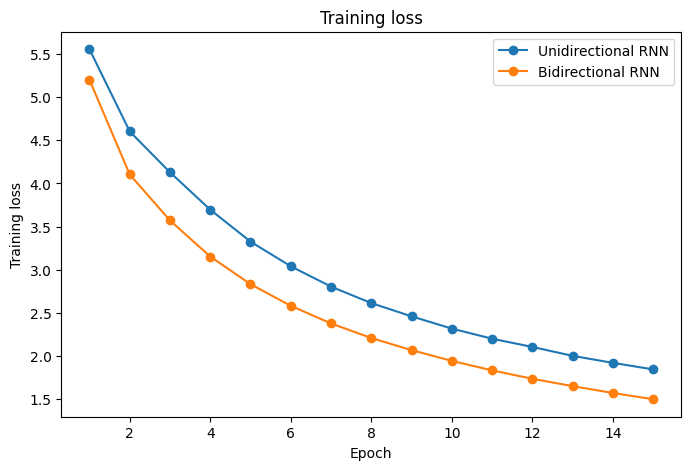

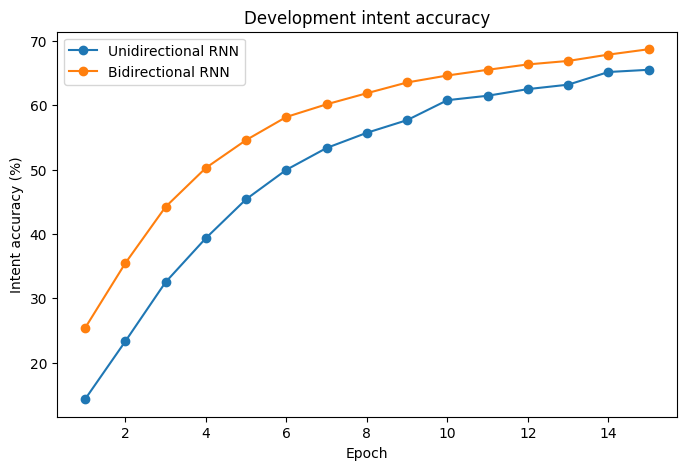

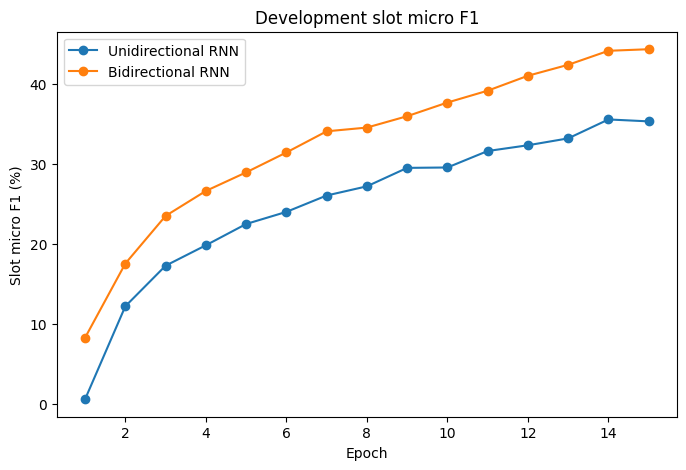

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(rnn_history['epoch'], rnn_history['training_loss'], marker='o', label='Unidirectional RNN')
plt.plot(birnn_history['epoch'], birnn_history['training_loss'], marker='o', label='Bidirectional RNN')
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('Training loss')
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(rnn_history['epoch'], rnn_history['dev_intent_accuracy'], marker='o', label='Unidirectional RNN')
plt.plot(birnn_history['epoch'], birnn_history['dev_intent_accuracy'], marker='o', label='Bidirectional RNN')
plt.xlabel('Epoch')
plt.ylabel('Intent accuracy (%)')
plt.title('Development intent accuracy')
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(rnn_history['epoch'], rnn_history['dev_slot_micro_f1'], marker='o', label='Unidirectional RNN')
plt.plot(birnn_history['epoch'], birnn_history['dev_slot_micro_f1'], marker='o', label='Bidirectional RNN')
plt.xlabel('Epoch')
plt.ylabel('Slot micro F1 (%)')
plt.title('Development slot micro F1')
plt.legend()
plt.show()


## 14. Final test evaluation

After choosing the model using the development set, evaluate it once on the test set. Both metrics are reported as percentages with two decimal places.

- Intent accuracy: correct intent predictions divided by the number of utterances.
- Slot micro F1: exact slot type and token-span matches, pooled across all test utterances.


In [14]:
test_scores = get_scores(best_model, data['test'])

print('Selected model:', best_name)
print(f'Test intent accuracy: {test_scores["intent_accuracy"]:.2f}%')
print(f'Test slot micro F1: {test_scores["slot_micro_f1"]:.2f}%')


Selected model: Bidirectional RNN
Test intent accuracy: 68.86%
Test slot micro F1: 41.24%


## Readable slot extraction output

The model continues to train and predict using BIO tags (`B-time`, `I-time`, `O`, etc.), since these labels identify token boundaries. For the final output, consecutive BIO tags are decoded into readable slot-value pairs such as `[time: five am]`.

The test prediction CSV stores the readable values in `true_slots` and `predicted_slots`. The original token-level BIO sequences are also retained in `true_bio_tags` and `predicted_bio_tags` for debugging and evaluation.

## 15. Test predictions and output files

The output folder contains the test predictions for both tasks, the development comparison and the final test metrics.

In [15]:
OUTPUT_DIR = Path('task1_task2_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

test_loader = DataLoader(
    MASSIVEDataset(data['test']),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=make_batch
)

prediction_rows = []
best_model.eval()

with torch.no_grad():
    for words, lengths, intent_labels, slot_labels in test_loader:
        words = words.to(DEVICE)
        intent_scores, slot_scores = best_model(words, lengths)

        intent_predictions = intent_scores.argmax(dim=1).cpu().tolist()
        slot_predictions = slot_scores.argmax(dim=2).cpu().tolist()

        for i, predicted_intent in enumerate(intent_predictions):
            length = lengths[i].item()
            predicted_slots = slot_predictions[i][:length]
            row_index = len(prediction_rows)
            original = data['test'][row_index]

            prediction_rows.append({
                'id': original['id'],
                'utterance': original['utt'],
                'true_intent': original['intent'],
                'predicted_intent': id2intent[predicted_intent],
                # Human-readable slot extraction: [slot_type: slot span]
                'true_slots': format_slot_values(
                    original['tokens'], original['slots']
                ),
                'predicted_slots': format_slot_values(
                    original['tokens'],
                    [id2slot[tag] for tag in predicted_slots]
                ),
                # Keep token-level BIO tags as optional diagnostic columns.
                'true_bio_tags': ' '.join(original['slots']),
                'predicted_bio_tags': ' '.join(
                    id2slot[tag] for tag in predicted_slots
                )
            })

pd.DataFrame(prediction_rows).to_csv(
    OUTPUT_DIR / 'test_predictions.csv',
    index=False
)

results.to_csv(OUTPUT_DIR / 'development_comparison.csv', index=False, float_format='%.2f')

pd.DataFrame([{
    'selected_model': best_name,
    **test_scores
}]).to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False, float_format='%.2f')

torch.save({
    'model_state': best_model.state_dict(),
    'vocab': vocab,
    'intent2id': intent2id,
    'slot2id': slot2id,
    'embedding_dim': EMBEDDING_DIM,
    'hidden_dim': HIDDEN_DIM,
    'bidirectional': best_name == 'Bidirectional RNN'
}, OUTPUT_DIR / 'best_joint_rnn.pt')

print('Files saved in:', OUTPUT_DIR.resolve())


Files saved in: /content/task1_task2_outputs


## 16. Predict an intent and slots for a new utterance

This uses the same tokenisation and vocabulary as the training data. The model returns one intent and one slot label for each token.

If the correct labels are supplied, the cell can compare the prediction with them. The slot span F1 shown for one utterance is only an example-level check; the official **slot micro F1** is calculated by pooling exact span matches across the full development or test set in Section 9.


In [16]:
def predict_utterance(utterance):
    words = tokenize_utterance(utterance)

    if not words:
        words = [UNK_TOKEN]

    word_ids = [vocab.get(word, UNK_ID) for word in words]
    input_words = torch.tensor(
        [word_ids],
        dtype=torch.long,
        device=DEVICE
    )
    lengths = torch.tensor([len(word_ids)], dtype=torch.long)

    best_model.eval()

    with torch.no_grad():
        intent_scores, slot_scores = best_model(input_words, lengths)

        intent_id = int(intent_scores.argmax(dim=1).item())
        slot_ids = slot_scores.argmax(dim=2)[0].cpu().tolist()

    predicted_intent = id2intent[intent_id]
    predicted_slots = [
        id2slot[index] for index in slot_ids[:len(words)]
    ]

    extracted_slots = extract_slot_values(words, predicted_slots)

    result = {
        'utterance': utterance,
        'predicted_intent': predicted_intent,
        'tokens': words,
        # Readable output requested: [slot_type: slot span]
        'predicted_slots': extracted_slots,
        # BIO tags are retained for debugging/evaluation if needed.
        'predicted_bio_tags': predicted_slots
    }

    return result


# Predict intent and slots for a new utterance.
result = predict_utterance('Set an alarm for 7 am tomorrow')

print('Utterance:', result['utterance'])
print('Predicted intent:', result['predicted_intent'])
print('Tokens:', result['tokens'])
print('Extracted slots:', '; '.join(result['predicted_slots']) if result['predicted_slots'] else 'No slots detected')
print('BIO tags:', result['predicted_bio_tags'])



Utterance: Set an alarm for 7 am tomorrow
Predicted intent: alarm_set
Tokens: ['set', 'an', 'alarm', 'for', '7', 'am', 'tomorrow']
Extracted slots: [time: 7 am]; [date: tomorrow]
BIO tags: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'B-date']
